# Checking the theoretical assumptions of the order-book model

This notebook tests each assumption behind the theoretical results in **Section 3.2** and **Supplementary Section 8** of the manuscript, using the model code in this repository. For each one it shows where the theory holds and where it breaks down.

| Section | Assumption or result tested |
|---|---|
| 1 | Reservation price and linear order size (Eq. 10, Section 8.2) |
| 2 | Common risk aversion: exact under log utility, first order otherwise |
| 3 | Fast clearing: reservation prices converge to the competitive-equilibrium price |
| 4 | Whale distortion without herding, $\delta_S=\rho\Delta_S$ (Eq. 11) |
| 5 | Whale distortion with herding (Eqs. 12–13) |
| 6 | Convergence: $\kappa$, $T_\epsilon$, and the sign of $\partial\kappa/\partial h$ |
| 7 | Expected dynamics: signal noise and order-book noise |
| 8 | Fixed true outcome |
| 9 | Fixed whale wealth share: what happens when the whale stops trading |
| 10 | Remake of the collaborator's whale figure (P1–P3) |
| 11 | Summary |

Unless stated otherwise, all agents have **log utility** ($r_i = 1$), budgets $B_{i,0}\sim U(100,1000)$, stubbornness $s=0.3$, and there are 100 non-whale agents; the true outcome is $\eta=0.5$ and the whale's valuation is $W=0.7$ ($\Delta_S=0.2$). The market price $m_t$ is the end-of-period price of Eq. 2 (midquote, else the remaining best quote, else the last trade).

Simulation results are cached in `theory_checks/cache/`; delete that folder to rerun everything (about 10 minutes on 8 cores).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import theory_helpers as th          # also puts the repository root on the path
from bettor import bettor
from theory_helpers import cached, parallel_map, ETA, W, TICK

DELTA = W - ETA
SEEDS = range(3)
warnings.filterwarnings("ignore", message="Mean of empty slice")   # periods where the book is one-sided

# Plot style: one blue ramp for ordered quantities, blue/orange for two-way comparisons
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
RAMP = ["#86b6ef", "#2a78d6", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
    "lines.linewidth": 2})
DOT = dict(marker="o", ms=7, mec=SURFACE, mew=1.2, ls="none")
SQUARE = dict(DOT, marker="s")

## 1. Reservation price and linear order size

**Theory (Section 8.2).** An agent's reservation price is
$z = V / \big(V + (1-V)\,((B+C)/B)^{r}\big)$: it buys below $z$ and sells above it. The order size at price $p$ is approximated by Eq. 10,
$x^\star(p) \approx -C + \frac{B+pC}{r\,p(1-p)}(V-p)$, which is exact under log utility.

**Test.** Compare Eq. 10 with the model's own optimiser, `bettor.trade(p)`, for an agent with $V = 0.6$ and $B = 500$, with no holdings and with a long position.

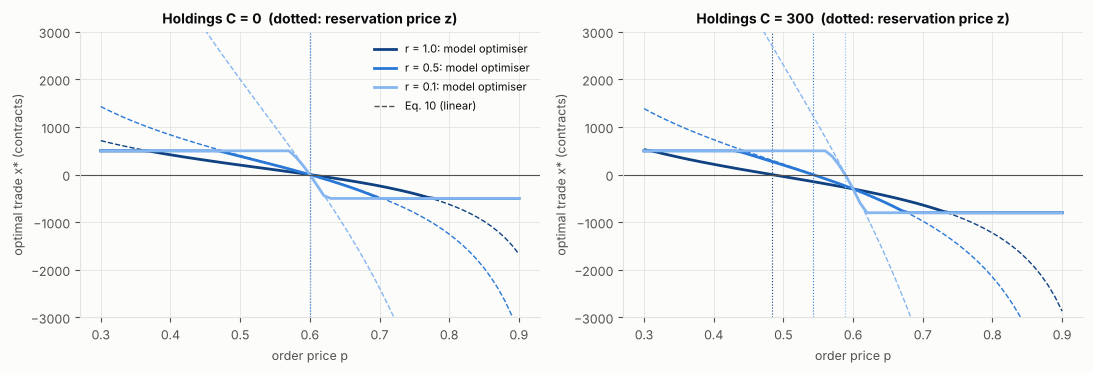

In [2]:
prices = np.linspace(0.3, 0.9, 61)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, holdings in zip(axes, [0, 300]):
    for r, color in zip([1.0, 0.5, 0.1], RAMP[::-1]):
        agent = bettor(budget=500.0, market_valuation=0.6, n_contracts=holdings, risk_av=r)
        exact = [agent.trade(p) for p in prices]
        linear = -holdings + (500 + prices * holdings) / (r * prices * (1 - prices)) * (0.6 - prices)
        ax.plot(prices, exact, color=color, label=f"r = {r}: model optimiser")
        ax.plot(prices, linear, color=color, lw=1, ls="--")
        ax.axvline(agent.reservation_price(), color=color, lw=0.8, ls=":")
    ax.set(title=f"Holdings C = {holdings}  (dotted: reservation price z)", xlabel="order price p",
           ylabel="optimal trade x* (contracts)", ylim=(-3000, 3000))
    ax.axhline(0, color=MUTED, lw=0.8)
axes[0].plot([], [], color=MUTED, lw=1, ls="--", label="Eq. 10 (linear)")
axes[0].legend(loc="upper right")
plt.tight_layout()

**Takeaway.** For $r=1$ Eq. 10 matches the optimiser exactly until the order reaches the code's per-order trading range (at most $\lfloor B\rfloor$ contracts bought, $\lfloor B\rfloor + C$ sold; flat sections). That cap is stricter than full collateralisation and binds far from the reservation price. For $r=0.5$ Eq. 10 is accurate only near $p=z$, and for $r=0.1$ demand is so elastic that the agent hits the cap almost immediately. A long position ($C>0$) lowers the reservation price below $V=0.6$, as the theory says.

## 2. Common risk aversion: exact under log utility, first order otherwise

**Theory.** With fast clearing, the market price is the competitive-equilibrium price. Under log utility this is exactly the wealth-weighted mean valuation; for other CRRA preferences it holds to first order with weights $B_i/r_i$ (Section 8.3), and the exact price is shaded towards $\tfrac12$ when $r<1$.

**Test.** Hold beliefs fixed (stubbornness 1, no signal noise), with valuations $V_i \sim N(0.6, 0.08)$, and let the order book trade for 80 periods. Compare the settled price with the exact competitive-equilibrium price (root of aggregate CRRA demand) and with the linear weighted average, for four risk-aversion settings.

In [3]:
settings = list(th.RISK_SETTINGS)
jobs = [(seed, kind) for kind in settings for seed in SEEDS]
fixed = cached("fixed_beliefs", lambda: dict(zip(jobs, parallel_map(th.fixed_belief_market, jobs))))

rows = []
for kind in settings:
    runs = [fixed[(seed, kind)] for seed in SEEDS]
    rows.append({"risk aversion": kind,
                 "simulated price (last 20 periods)": np.mean([r["price"][-20:].mean() for r in runs]),
                 "exact equilibrium price": np.mean([r["walras"] for r in runs]),
                 "linear B/r-weighted mean": np.mean([r["linear"] for r in runs]),
                 "final reservation-price range (10-90%)": np.mean([r["z_iqr"][-1] for r in runs])})
pd.DataFrame(rows).round(3)

,risk aversion,simulated price (last 20 periods),exact equilibrium price,linear B/r-weighted mean,final reservation-price range (10-90%)
0,r = 1,0.595,0.594,0.594,0.010
1,r = 0.5,0.594,0.592,0.594,0.007
2,"r ~ U(0.2, 1)",0.582,0.580,0.584,0.010
3,"r ~ U(0, 1)",0.575,0.576,0.596,0.010


**Takeaway.** In every setting the order book settles within about a tick of the exact competitive-equilibrium price. With $r=1$ that price equals the wealth-weighted mean valuation (the linear formula is exact). With a common $r=0.5$ the exact price is shaded slightly towards $\tfrac12$, but by less than a tick here. With heterogeneous $r$ the linear $B/r$-weighted mean misses the equilibrium: by about 2 ticks for $r\sim U(0,1)$, because near-risk-neutral agents' demand is capped rather than proportional to $1/r$. So it is the closed-form formula, not the convergence to equilibrium, that fails when risk aversion varies.

## 3. Fast clearing

**Theory.** Repeated trading brings all reservation prices to within about one tick of a common price (assumption in Section 8.1). This is an idealised limit, not a property of the order book.

**Test.** Using the same fixed-belief runs, track the spread of reservation prices (10th–90th percentile) and the quoted bid–ask spread over time.

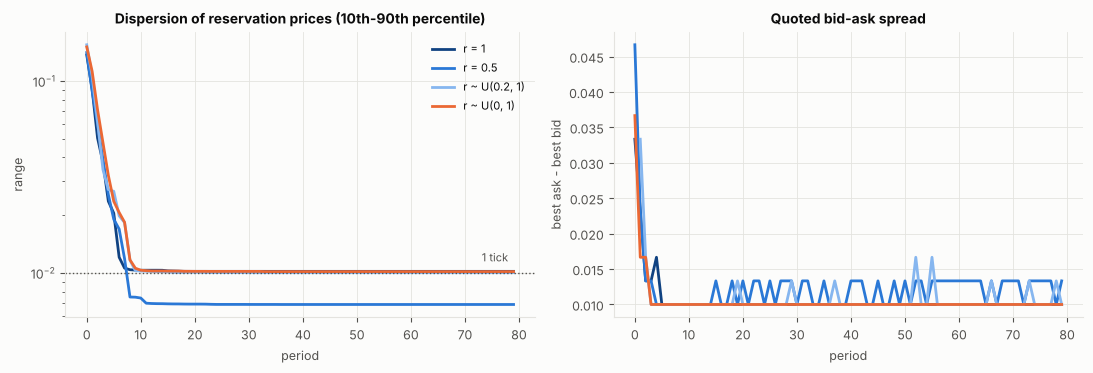

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = dict(zip(settings, ["#104281", "#2a78d6", "#86b6ef", ORANGE]))
for kind in settings:
    runs = [fixed[(seed, kind)] for seed in SEEDS]
    axes[0].plot(np.mean([r["z_iqr"] for r in runs], 0), color=colors[kind], label=kind)
    axes[1].plot(np.nanmean([r["spread"] for r in runs], 0), color=colors[kind], label=kind)
axes[0].axhline(TICK, color=MUTED, lw=1, ls=":"); axes[0].text(78, TICK * 1.15, "1 tick", ha="right", color=MUTED, fontsize=8)
axes[0].set(yscale="log", title="Dispersion of reservation prices (10th-90th percentile)", xlabel="period", ylabel="range")
axes[1].set(title="Quoted bid-ask spread", xlabel="period", ylabel="best ask - best bid")
axes[0].legend(loc="upper right")
plt.tight_layout()

**Takeaway.** With beliefs held fixed, reservation prices compress to about one tick within roughly ten periods in all four settings, and the quoted spread falls to one or two ticks. Fast clearing is therefore a good description of the steady state when beliefs are stable. When beliefs keep moving (signal noise, Section 7), the book never fully settles and prices fluctuate around the equilibrium.

## 4. Whale distortion without herding: $\delta_S = \rho\,\Delta_S$ (Eq. 11)

**Theory.** A whale with wealth share $\rho$ and misvaluation $\Delta_S$ shifts the steady-state price by $\delta_S = \rho\Delta_S$, where $\rho$ is the whale's *mark-to-market* wealth share in the steady state, $\rho_S$, approximately its initial budget share. Eq. 11 also assumes non-whale valuation errors average out.

**Test.** For each $\rho$, average the price error over periods 40–119 (three runs), with no signal noise and with signal standard deviation 0.1. Also record the whale's mark-to-market wealth share at the end.

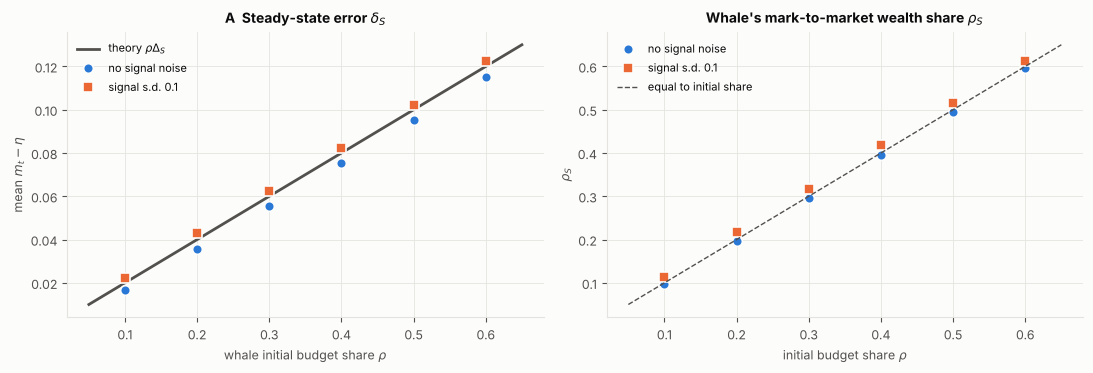

In [5]:
jobs = [(rho, noise, seed) for rho in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6] for noise in [0.0, 0.1] for seed in SEEDS]
whale = cached("whale_steady_state", lambda: dict(zip(jobs, parallel_map(th.whale_steady_state, jobs))))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rhos = sorted({j[0] for j in jobs}); grid = np.linspace(0.05, 0.65, 50)
axes[0].plot(grid, grid * DELTA, color=MUTED, label=r"theory $\rho\Delta_S$")
for noise, color, style, label in [(0.0, BLUE, DOT, "no signal noise"), (0.1, ORANGE, SQUARE, "signal s.d. 0.1")]:
    means = [np.mean([whale[(rho, noise, s)]["error"] for s in SEEDS]) for rho in rhos]
    axes[0].plot(rhos, means, color=color, label=label, **style)
    axes[1].plot(rhos, [np.mean([whale[(rho, noise, s)]["rho_S"] for s in SEEDS]) for rho in rhos], color=color, label=label, **style)
axes[1].plot(grid, grid, color=MUTED, lw=1, ls="--", label="equal to initial share")
axes[0].set(title=r"A  Steady-state error $\delta_S$", xlabel=r"whale initial budget share $\rho$", ylabel=r"mean $m_t-\eta$")
axes[1].set(title=r"Whale's mark-to-market wealth share $\rho_S$", xlabel=r"initial budget share $\rho$", ylabel=r"$\rho_S$")
axes[0].legend(loc="upper left"); axes[1].legend(loc="upper left")
plt.tight_layout()

**Takeaway.** The steady-state error follows $\rho\Delta_S$ to within about a tick, with and without signal noise. The whale's mark-to-market wealth share stays close to its initial budget share, so using the initial share is a good approximation.

## 5. Whale distortion with herding (Eqs. 12–13)

**Theory.** With common herding weight $h$ and stubbornness $s$, herding agents' valuations settle a fraction $h/(1-(1-h)s)$ of the way to the distorted price (Eq. 12), so
$\delta_S = \rho\Delta_S\,\frac{(1-h)(1-s)+h}{(1-h)(1-s)+h\rho}$ (Eq. 13), rising to $\Delta_S$ as $h\to1$.

**Test.** Steady-state error against $h$ for $\rho = 0.2$ and $0.4$ (panel B), and the price path after a whale enters (panel C).

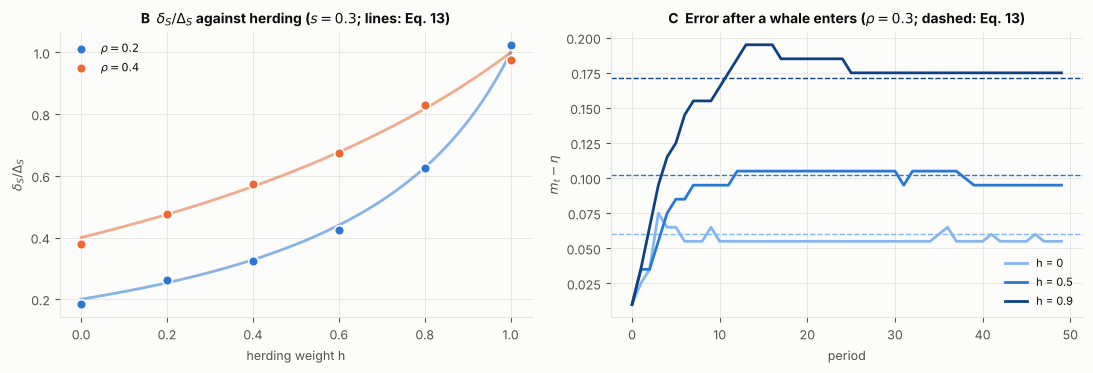

In [6]:
herd_jobs = [(rho, 0.0, 0, h) for rho in [0.2, 0.4] for h in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]]
herd = cached("herding_steady_state", lambda: dict(zip(herd_jobs, parallel_map(th.whale_steady_state, herd_jobs))))
paths = cached("whale_entry", lambda: dict(zip([0.0, 0.5, 0.9], parallel_map(th.whale_entry_path, [(h,) for h in [0.0, 0.5, 0.9]]))))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
grid = np.linspace(0, 1, 60)
for rho, color in [(0.2, BLUE), (0.4, ORANGE)]:
    axes[0].plot(grid, th.steady_state_error(rho, grid, 0.3) / DELTA, color=color, alpha=0.55)
    hs = [j[3] for j in herd_jobs if j[0] == rho]
    axes[0].plot(hs, [herd[(rho, 0.0, 0, h)]["error"] / DELTA for h in hs], color=color, label=rf"$\rho={rho}$", **DOT)
axes[0].set(title=r"B  $\delta_S/\Delta_S$ against herding ($s=0.3$; lines: Eq. 13)", xlabel="herding weight h", ylabel=r"$\delta_S/\Delta_S$")
axes[0].legend(loc="upper left")
for (h, path), color in zip(paths.items(), RAMP):
    axes[1].plot(path, color=color, label=f"h = {h:g}")
    axes[1].axhline(th.steady_state_error(0.3, h, 0.3), color=color, lw=1, ls="--")
axes[1].set(title=r"C  Error after a whale enters ($\rho=0.3$; dashed: Eq. 13)", xlabel="period", ylabel=r"$m_t-\eta$")
axes[1].legend(loc="lower right")
plt.tight_layout()

**Takeaway.** Eq. 13 matches the simulations across the full range of $h$: herding amplifies the whale's distortion, and at $h=1$ the price adopts the whale's valuation. The distortion builds over roughly 5–15 periods and then stays: the whale is a persistent pull, not a one-off shock.

## 6. Convergence: $\kappa$, first passage, and the sign of $\partial\kappa/\partial h$

**Theory.** If the market clears within each period, $\delta_t-\delta_S=\kappa^t(\delta_0-\delta_S)$ with $\kappa=(1-h)s+h(1-\rho)$, the first-passage time is $T_\epsilon=\lceil \ln(\epsilon/|\delta_0-\delta_S|)/\ln\kappa\rceil$, and $\partial\kappa/\partial h = 1-\rho-s$: herding slows convergence if $s<1-\rho$ and speeds it up if $s>1-\rho$.

**Test.** Let the market settle, shock all non-whale valuations by $-0.15$, and track recovery to the settled level (three runs per setting), with no whale and with a whale ($\rho=0.3$). $\kappa$ is fitted by log-linear regression on errors larger than 1.5 ticks.

,rho,s,h,kappa (theory),kappa (fitted),T_eps (theory),first passage (sim)
0,0.0,0.1,0.0,0.10,0.11,1.0,1.00
1,0.0,0.1,0.3,0.37,0.37,3.0,2.67
2,0.0,0.1,0.6,0.64,0.72,5.0,4.33
3,0.0,0.3,0.0,0.30,0.36,2.0,1.67
4,0.0,0.3,0.3,0.51,0.56,3.0,3.00
5,0.0,0.3,0.6,0.72,0.73,7.0,5.67
6,0.0,0.6,0.0,0.60,0.65,4.0,4.67
7,0.0,0.6,0.3,0.72,0.74,7.0,6.67
8,0.0,0.6,0.6,0.84,0.85,12.0,13.00
9,0.3,0.2,0.0,0.20,NaN,2.0,1.00


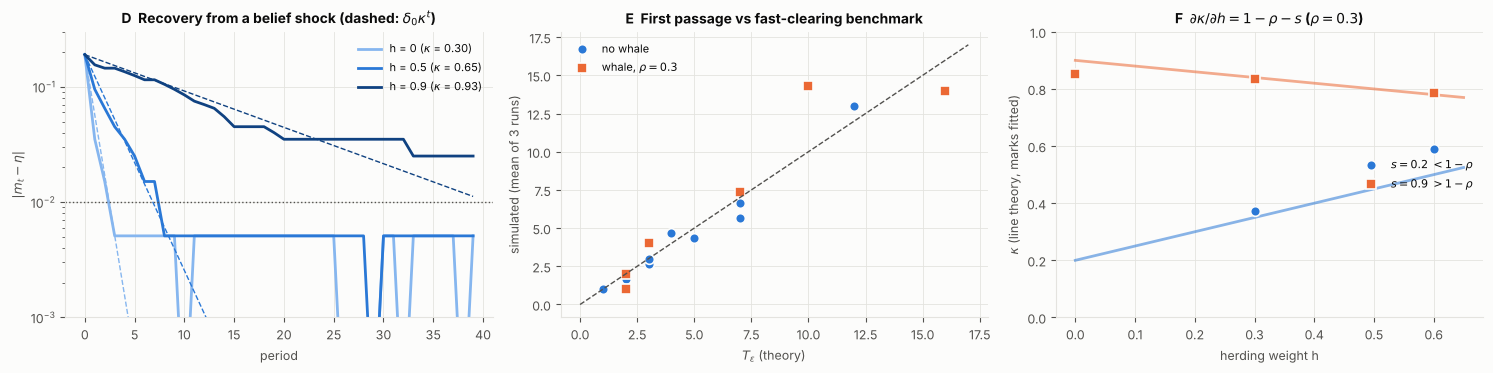

In [7]:
shock_settings = [(rho, s, h) for rho, s in [(0.0, 0.1), (0.0, 0.3), (0.0, 0.6), (0.3, 0.2), (0.3, 0.9)] for h in [0.0, 0.3, 0.6]]
jobs = [(rho, s, h, seed) for rho, s, h in shock_settings for seed in SEEDS]
recovery = cached("shock_recovery", lambda: dict(zip(jobs, parallel_map(th.recovery_after_shock, jobs))))
no_whale_paths = cached("belief_shock", lambda: dict(zip([0.0, 0.5, 0.9], parallel_map(th.belief_shock_path, [(h,) for h in [0.0, 0.5, 0.9]]))))

rows = []
for rho, s, h in shock_settings:
    errors = [recovery[(rho, s, h, seed)] for seed in SEEDS]
    t_fit = np.concatenate([np.flatnonzero(np.abs(e) > 0.015)[:8] for e in errors])
    log_fit = np.concatenate([np.log(np.abs(e[np.flatnonzero(np.abs(e) > 0.015)[:8]])) for e in errors])
    kappa = th.convergence_factor(rho, h, s)
    rows.append({"rho": rho, "s": s, "h": h, "kappa (theory)": kappa,
                 "kappa (fitted)": np.exp(np.polyfit(t_fit, log_fit, 1)[0]) if len(set(t_fit)) >= 2 else np.nan,
                 "T_eps (theory)": th.first_passage_benchmark((1 - rho) * -0.15, kappa, 0.02),
                 "first passage (sim)": np.nanmean([th.first_passage(e, 0.02) for e in errors])})
convergence = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for (h, path), color in zip(no_whale_paths.items(), RAMP):
    k = th.convergence_factor(0.0, h, 0.3); t = np.arange(len(path))
    axes[0].plot(t, np.abs(path) + 1e-4, color=color, label=rf"h = {h:g} ($\kappa$ = {k:.2f})")
    axes[0].plot(t, abs(path[0]) * k ** t, color=color, lw=1, ls="--")
axes[0].axhline(TICK, color=MUTED, lw=1, ls=":")
axes[0].set(yscale="log", ylim=(1e-3, 0.3), title=r"D  Recovery from a belief shock (dashed: $\delta_0\kappa^t$)", xlabel="period", ylabel=r"$|m_t-\eta|$")
axes[0].legend(loc="upper right")
for has_whale, color, style, label in [(False, BLUE, DOT, "no whale"), (True, ORANGE, SQUARE, r"whale, $\rho=0.3$")]:
    sub = convergence[(convergence["rho"] > 0) == has_whale]
    axes[1].plot(sub["T_eps (theory)"], sub["first passage (sim)"], color=color, label=label, **style)
axes[1].plot([0, 17], [0, 17], color=MUTED, lw=1, ls="--")
axes[1].set(title="E  First passage vs fast-clearing benchmark", xlabel=r"$T_\epsilon$ (theory)", ylabel="simulated (mean of 3 runs)")
axes[1].legend(loc="upper left")
grid = np.linspace(0, 0.65, 40)
for s, color, style in [(0.2, BLUE, DOT), (0.9, ORANGE, SQUARE)]:
    axes[2].plot(grid, th.convergence_factor(0.3, grid, s), color=color, alpha=0.55)
    sub = convergence[(convergence["rho"] == 0.3) & (convergence["s"] == s)]
    axes[2].plot(sub["h"], sub["kappa (fitted)"], color=color, label=rf"$s={s}$" + (r" $<1-\rho$" if s < 0.7 else r" $>1-\rho$"), **style)
axes[2].set(title=r"F  $\partial\kappa/\partial h=1-\rho-s$ ($\rho=0.3$)", xlabel="herding weight h", ylabel=r"$\kappa$ (line theory, marks fitted)", ylim=(0, 1))
axes[2].legend(loc="center right")
plt.tight_layout()
convergence.round(2)

**Takeaway.** Recovery decays at close to the predicted $\kappa$, and first-passage times track $T_\epsilon$, typically a few periods slower (finite liquidity). The reversal of the herding effect at $s=1-\rho$ appears in the simulations. Two limits: with strong herding and no whale the price can stall a few ticks from equilibrium (panel D, $h=0.9$), and when $\kappa$ is small the error falls below the tick within one or two periods, so $\kappa$ cannot be estimated (missing fits).

## 7. Expected dynamics: signal noise and order-book noise

**Theory.** Results take expectations over private signals, so signal noise averages out in aggregate demand, and the order book is assumed to clear.

**Test.** Without a whale, compare each period's market price $m_t$ with the log-utility equilibrium price of that period's valuations, $p^*_t$ (wealth-weighted mean valuation). The difference $\mu_t = m_t - p^*_t$ is noise created by the order book. Vary the signal noise (dispersion of valuations) and herding.

*Note.* The code draws signals with **standard deviation** $1-e_i$, whereas Eqs. 4–5 of the manuscript state **variance** $1-e_i$.

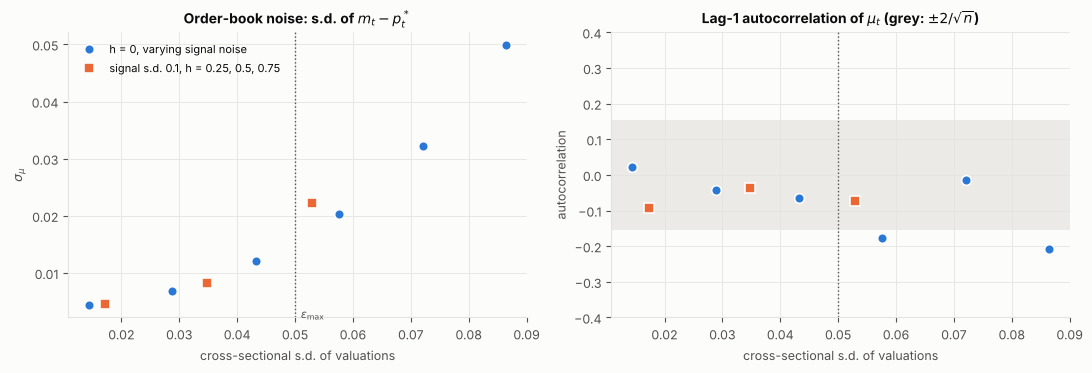

In [8]:
jobs = [(noise, 0.0, 0) for noise in [0.02, 0.04, 0.06, 0.08, 0.10, 0.12]] + [(0.1, h, 0) for h in [0.25, 0.5, 0.75]]
noise = cached("order_book_noise", lambda: dict(zip(jobs, parallel_map(th.noise_run, jobs))))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for herding, color, style, label in [(False, BLUE, DOT, "h = 0, varying signal noise"), (True, ORANGE, SQUARE, "signal s.d. 0.1, h = 0.25, 0.5, 0.75")]:
    runs = [noise[j] for j in jobs if (j[1] > 0) == herding]
    axes[0].plot([r["dispersion"] for r in runs], [r["sigma_mu"] for r in runs], color=color, label=label, **style)
    axes[1].plot([r["dispersion"] for r in runs], [r["autocorr"] for r in runs], color=color, label=label, **style)
for ax in axes:
    ax.axvline(0.05, color=MUTED, lw=1, ls=":"); ax.set_xlabel("cross-sectional s.d. of valuations")
axes[0].text(0.051, 0.002, r"$\epsilon_{\max}$", color=MUTED, fontsize=8)
band = 2 / np.sqrt(noise[jobs[0]]["n"])
axes[1].axhspan(-band, band, color=GRID, alpha=0.7, lw=0)
axes[0].set(title=r"Order-book noise: s.d. of $m_t-p^*_t$", ylabel=r"$\sigma_\mu$")
axes[1].set(title=r"Lag-1 autocorrelation of $\mu_t$ (grey: $\pm2/\sqrt{n}$)", ylabel="autocorrelation", ylim=(-0.4, 0.4))
axes[0].legend(loc="upper left")
plt.tight_layout()

**Takeaway.** When valuations are dispersed by less than the maximum price offset ($\epsilon_{\max} = 0.05$), order-book noise is small, about a quarter of the dispersion. Above it, noise grows sharply. The manuscript's default population (expertise $\approx 0.9$, $s \approx 0.3$) has dispersion of about 0.07, so it is in the noisy regime: prices fluctuate around the theoretical level by several ticks. The noise is close to serially uncorrelated, slightly negative in the noisiest runs.

## 8. Fixed true outcome

**Theory.** Steady states are derived with $\eta$ fixed. In the model $\eta_t$ follows a random walk (Eq. 1).

**Test.** One run with a whale ($\rho=0.3$), signal s.d. 0.1 and a random-walk true outcome (step s.d. 0.02). If the whale's pull holds period by period, the price should track $\eta_t + \rho\,(W-\eta_t)$, not $\eta_t$.

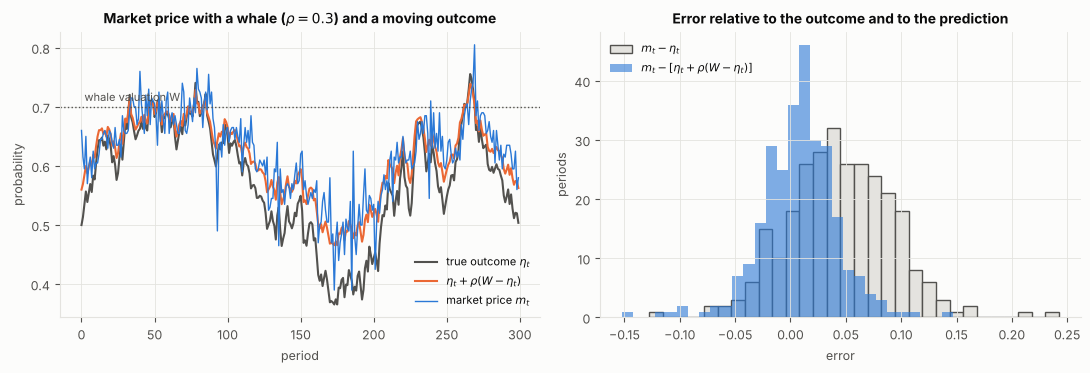

In [9]:
def whale_with_random_walk(seed=3, periods=300, rho=0.3):
    population = th.add_whale(th.make_population(seed, noise=0.1), rho)
    eta = th.random_walk(seed, periods, sd=0.02)
    return th.simulate(population, periods, th.seeded(seed), eta_path=eta)

walk = cached("random_walk_whale", whale_with_random_walk)
predicted = walk["eta"] + 0.3 * (W - walk["eta"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(walk["eta"], color=MUTED, lw=1.5, label=r"true outcome $\eta_t$")
axes[0].plot(predicted, color=ORANGE, lw=1.5, label=r"$\eta_t+\rho(W-\eta_t)$")
axes[0].plot(walk["price"], color=BLUE, lw=1, label="market price $m_t$")
axes[0].axhline(W, color=MUTED, lw=1, ls=":"); axes[0].text(2, W + 0.01, "whale valuation W", color=MUTED, fontsize=8)
axes[0].set(title=r"Market price with a whale ($\rho=0.3$) and a moving outcome", xlabel="period", ylabel="probability")
axes[0].legend(loc="lower right")
axes[1].hist(walk["price"][20:] - walk["eta"][20:], bins=30, color=GRID, edgecolor=MUTED, label=r"$m_t-\eta_t$")
axes[1].hist(walk["price"][20:] - predicted[20:], bins=30, color=BLUE, alpha=0.6, label=r"$m_t-[\eta_t+\rho(W-\eta_t)]$")
axes[1].set(title="Error relative to the outcome and to the prediction", xlabel="error", ylabel="periods")
axes[1].legend(loc="upper left")
plt.tight_layout()

**Takeaway.** With a moving outcome the price tracks $\eta_t+\rho(W-\eta_t)$: the whale's pull is persistent, and its size changes as the outcome moves towards or away from $W$. The remaining error is centred within about two ticks of zero; its spread comes from order-book noise and the lag with which agents learn about $\eta_t$.

## 9. Fixed whale wealth share: what if the whale stops trading?

**Theory.** The results assume the whale stays in the market. What actually determines the distortion is the position $Q$ the whale holds. If the whale stops trading but keeps $Q$, the other agents remain net short $Q$ and only hold that position if the price stays above $\eta$:
$p-\eta \approx \frac{Q\,p(1-p)}{\Omega_N}\cdot\frac{(1-h)(1-s)+h}{(1-h)(1-s)}$, where $\Omega_N$ is non-whale wealth.

**Test.** A whale ($\rho = 0.3$) trades for 1, 3 or 30 periods, then stops trading but keeps its position.

,active,h,position,error_after,predicted
0,1,0.0,1189,0.005,0.005
1,3,0.0,9731,0.044,0.041
2,30,0.0,14126,0.055,0.059
3,1,0.5,1189,0.015,0.012
4,3,0.5,5637,0.055,0.057
5,30,0.5,9858,0.095,0.097


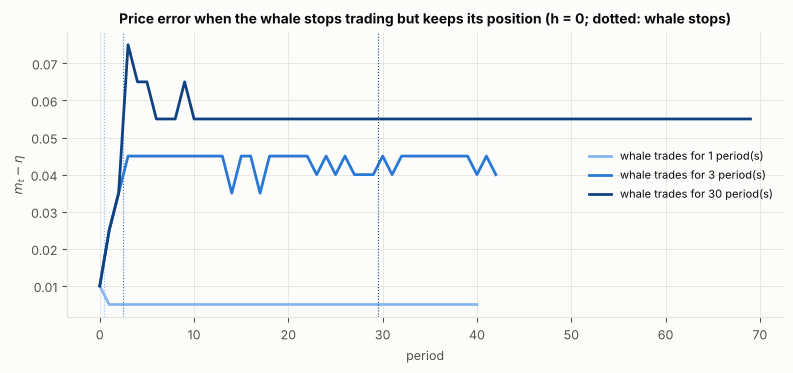

In [10]:
jobs = [(active, h) for h in [0.0, 0.5] for active in [1, 3, 30]]
held = cached("held_position", lambda: parallel_map(th.held_position, jobs))

fig, ax = plt.subplots(figsize=(8, 3.8))
for result, color in zip([r for r in held if r["h"] == 0.0], RAMP):
    ax.plot(result["path"], color=color, label=f"whale trades for {result['active']} period(s)")
    ax.axvline(result["active"] - 0.5, color=color, lw=0.8, ls=":")
ax.set(title="Price error when the whale stops trading but keeps its position (h = 0; dotted: whale stops)",
       xlabel="period", ylabel=r"$m_t-\eta$")
ax.legend(loc="center right")
plt.tight_layout()
pd.DataFrame([{k: v for k, v in r.items() if k != "path"} for r in held]).round(3)

**Takeaway.** The distortion does not decay when the whale stops trading; it is set by the position the whale holds. A single period of trading builds only a small position (about 1,200 contracts here) because a single order can only fill against the liquidity resting in the book. A reversion experiment therefore needs the whale to *sell its position back*, not just stop trading.

## 10. Remake of the collaborator's whale figure

The collaborator's code was not available, so this remake uses these definitions:

* **Population:** manuscript defaults (Table 1), including $r_i\sim U(0,1)$; the whale's risk aversion is also drawn from $U(0,1)$. The whale ($W = 0.7$) is present from period 0.
* **True outcome:** a random walk from 0.5 with step s.d. 0.05 (the code's default), 200 periods, 30 runs per $\rho$.
* **P1:** maximum of $|m_t-\eta_t|$ over the run.
* **P1b (pull):** least-squares slope of $m_t-\eta_t$ on $W-\eta_t$ through the origin, so 0 means the price tracks the outcome and 1 means it sits at the whale's valuation. Theory: pull $=\rho$.
* **Ordinary band:** 95th percentile of $|m_t-\eta_t|$ across all control runs ($\rho = 0$).
* **P2:** periods from the maximum error until $|m_t-\eta_t|$ is back within the band.
* **P3:** share of periods with $|m_t-\eta_t|$ above the band.

The same figure is then repeated with log utility for every agent (signal s.d. 0.1, $s = 0.3$), where the theory applies exactly.

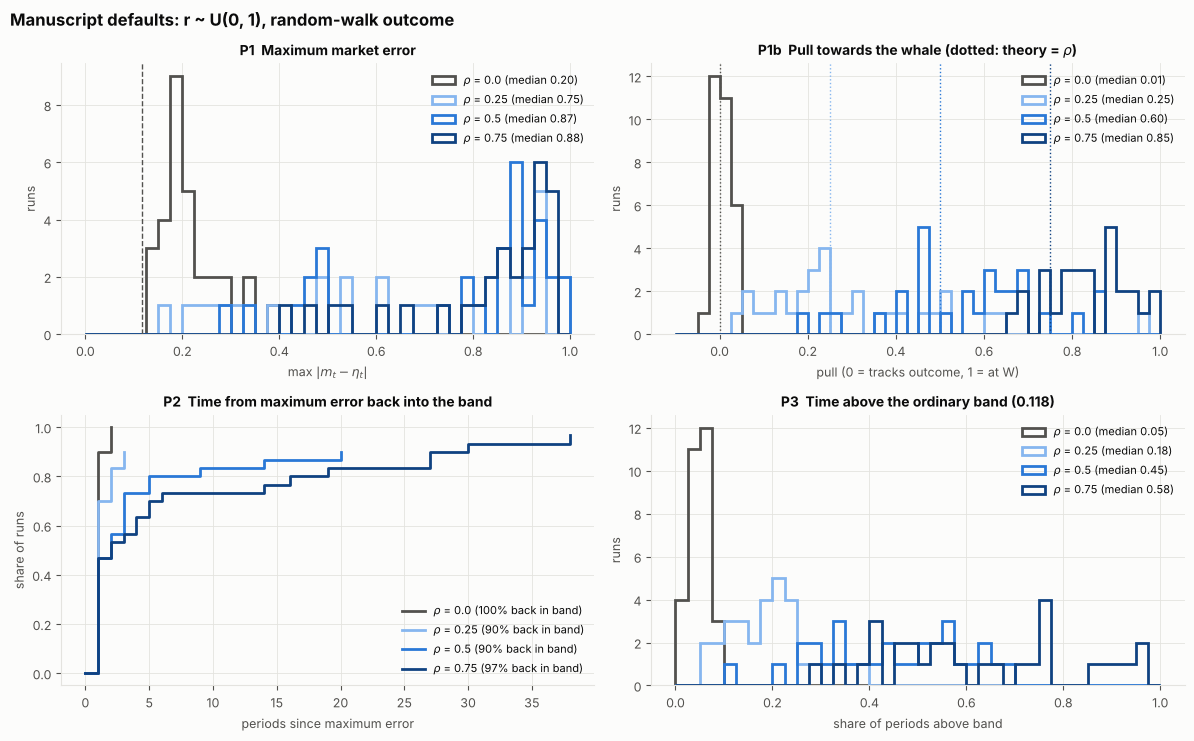

In [11]:
RHOS = [0.0, 0.25, 0.5, 0.75]
RUNS = range(30)
RHO_COLORS = {0.0: MUTED, 0.25: "#86b6ef", 0.5: "#2a78d6", 0.75: "#104281"}

def collaborator_metrics(kind):
    jobs = [(rho, seed, kind) for rho in RHOS for seed in RUNS]
    runs = cached(f"collaborator_{kind}", lambda: dict(zip(jobs, parallel_map(th.collaborator_run, jobs))))
    errors = {rho: [runs[(rho, s, kind)]["price"] - runs[(rho, s, kind)]["eta"] for s in RUNS] for rho in RHOS}
    band = np.percentile(np.abs(np.concatenate(errors[0.0])), 95)
    metrics = {}
    for rho in RHOS:
        rows = []
        for seed, error in zip(RUNS, errors[rho]):
            gap = W - runs[(rho, seed, kind)]["eta"]
            peak = int(np.argmax(np.abs(error)))
            back = np.flatnonzero(np.abs(error[peak:]) <= band)
            rows.append({"max_error": np.abs(error).max(),
                         "pull": float(np.sum(error * gap) / np.sum(gap ** 2)),
                         "reversion": float(back[0]) if len(back) else np.nan,
                         "above_band": float(np.mean(np.abs(error) > band))})
        metrics[rho] = pd.DataFrame(rows)
    return metrics, band

def collaborator_figure(metrics, band, title):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5)); a, b, c, d = axes.ravel()
    for rho in RHOS:
        m, color = metrics[rho], RHO_COLORS[rho]
        label = rf"$\rho$ = {rho} (median {{:.2f}})"
        a.hist(m["max_error"], bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=color, label=label.format(m["max_error"].median()))
        b.hist(m["pull"], bins=np.linspace(-0.1, 1, 45), histtype="step", lw=2, color=color, label=label.format(m["pull"].median()))
        b.axvline(rho, color=color, lw=1, ls=":")
        times = np.sort(m["reversion"].dropna())
        c.step(np.r_[0, times], np.arange(len(times) + 1) / len(m), where="post", color=color,
               label=rf"$\rho$ = {rho} ({m['reversion'].notna().mean():.0%} back in band)")
        d.hist(m["above_band"], bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=color, label=label.format(m["above_band"].median()))
    a.axvline(band, color=MUTED, lw=1, ls="--")
    a.set(title="P1  Maximum market error", xlabel=r"max $|m_t-\eta_t|$", ylabel="runs")
    b.set(title="P1b  Pull towards the whale (dotted: theory = $\\rho$)", xlabel="pull (0 = tracks outcome, 1 = at W)", ylabel="runs")
    c.set(title="P2  Time from maximum error back into the band", xlabel="periods since maximum error", ylabel="share of runs")
    d.set(title=f"P3  Time above the ordinary band ({band:.3f})", xlabel="share of periods above band", ylabel="runs")
    for ax in (a, b, d):
        ax.legend(loc="upper right")
    c.legend(loc="lower right")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    plt.tight_layout()

manuscript_metrics, manuscript_band = collaborator_metrics("manuscript")
collaborator_figure(manuscript_metrics, manuscript_band, "Manuscript defaults: r ~ U(0, 1), random-walk outcome")

,rho = 0.0,rho = 0.25,rho = 0.5,rho = 0.75
"median pull (r~U(0,1))",0.006,0.245,0.598,0.847
"IQR of pull (r~U(0,1))",0.026,0.234,0.217,0.135
median pull (r=1),-0.040,0.325,0.587,0.807
IQR of pull (r=1),0.046,0.172,0.210,0.150


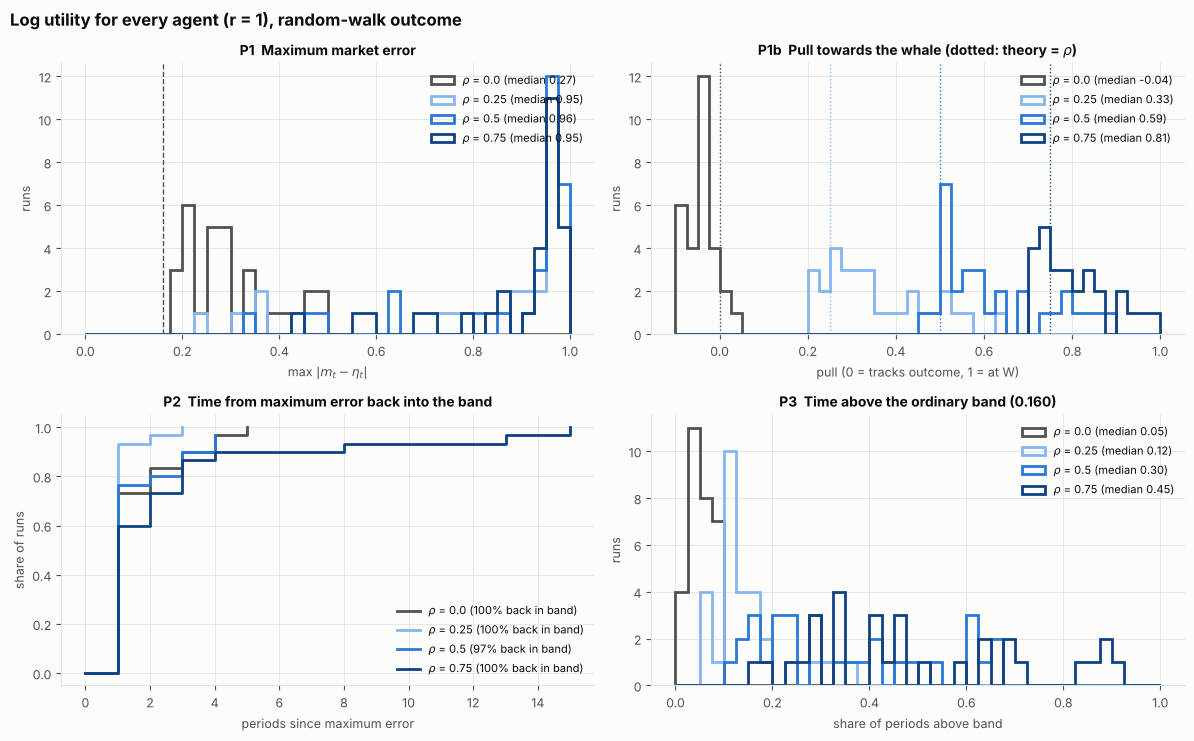

In [12]:
log_metrics, log_band = collaborator_metrics("log")
collaborator_figure(log_metrics, log_band, "Log utility for every agent (r = 1), random-walk outcome")
pd.DataFrame({f"rho = {rho}": {"median pull (r~U(0,1))": manuscript_metrics[rho]["pull"].median(),
                               "IQR of pull (r~U(0,1))": manuscript_metrics[rho]["pull"].quantile(0.75) - manuscript_metrics[rho]["pull"].quantile(0.25),
                               "median pull (r=1)": log_metrics[rho]["pull"].median(),
                               "IQR of pull (r=1)": log_metrics[rho]["pull"].quantile(0.75) - log_metrics[rho]["pull"].quantile(0.25)}
              for rho in RHOS}).round(3)

**Takeaways.**

* **P1b is the clearest summary and agrees with the theory.** The median pull is at or slightly above $\rho$ in both populations. The run-to-run spread is wide and similar with random and with common risk aversion, so it comes mainly from the moving outcome (step s.d. 0.05, often reaching 0 or 1) and order-book noise, not from the whale's random risk aversion.
* **P1 mixes the whale's effect with the moving outcome.** Maximum errors are large even in control runs, and with a whale they reach 0.8–0.9 when $\eta_t$ drifts far below $W$. The maximum says more about the outcome path than about the whale.
* **P2 measures how fast spikes subside, not reversion of the whale effect.** The maximum error is usually a short spike, so most runs are back in the band within a few periods, while the whale's pull remains (P1b, P3). This supports dropping P2.
* **P3 measures detectability.** It is the share of time the whale's distortion stands out from ordinary noise, which rises with $\rho$.
* **Scale differs from the collaborator's figure.** Their control runs had a median maximum error of 0.11 against 0.20 here, so their outcome path was less volatile (or fixed scenarios). The qualitative pattern is the same.

## 11. Summary

| Assumption | Holds? | Where it breaks down |
|---|---|---|
| Reservation price and Eq. 10 | Exact for $r=1$ | The code's per-order cap binds far from $z$; linear size inaccurate for small $r$ (Section 1) |
| Common risk aversion | Price = exact equilibrium in all settings; closed form exact for $r=1$ | Linear $B/r$ weights miss by about 2 ticks for $r\sim U(0,1)$ (Section 2) |
| Fast clearing | With fixed beliefs, reservation prices within a tick in about ten periods | With moving beliefs the book never settles (Sections 3, 7) |
| $\delta_S=\rho\Delta_S$ (Eq. 11) | Within about a tick, with or without signal noise | With a moving outcome, single runs vary widely around $\rho$ (Section 10) |
| Herding steady state (Eq. 13) | Matches for all $h$ | Needs common $h$, $s$ and unbiased agents |
| Convergence ($\kappa$, $T_\epsilon$) | Close; reversal at $s=1-\rho$ reproduced | Order-book friction adds a few periods; prices can stall with strong herding; tick limits estimation |
| Expected dynamics | Order-book noise small if valuation dispersion $<\epsilon_{\max}$ | Default population is in the noisy regime (Section 7) |
| Fixed true outcome | Price tracks $\eta_t+\rho(W-\eta_t)$ | Lag and noise around the prediction (Section 8) |
| Fixed whale share / presence | Distortion set by the position held | Stopping trading does not end the distortion; reversion needs the whale to unwind (Section 9) |